# Cuaderno de estudio · La estadística inferencial explicada con nuestro proyecto

Este cuaderno sigue el mismo orden de lecciones que la guía que te sirvió (`SKILL.md`), pero **cada ejemplo usa los números de nuestro proyecto** de los 10,000 clientes del banco.

**Cómo usarlo:**
1. Lee cada lección y ejecuta sus celdas.
2. Al final de cada lección hay una celda **🔗 Enlace con el documento**: dice qué apartado del documento cubre la lección y qué frase de la presentación sale de ella.
3. Después viene una celda **📝 Mis notas**: haz doble clic y escribe con tus palabras lo que entendiste.
4. Cada número que aparece dice **de dónde sale**, y junto a cada valor de tabla está la **función de Excel** que lo calcula.
5. La última sección, **Del cuaderno a la presentación**, junta todo en las conclusiones que hay que dar.

## Qué pide el documento del proyecto

El documento pide aplicar la inferencia estadística a un problema real: **estudiar una muestra para sacar conclusiones sobre la población, medir la incertidumbre y usar los resultados para tomar una decisión**. Lo organiza en 8 apartados más una sección obligatoria:

| Apartado del documento | Qué pide | Dónde se ve en este cuaderno |
|---|---|---|
| 1 · Planteamiento del problema | Qué se investiga, por qué importa, qué se quiere conocer, cuál es la población | Lección 1 y tabla de preguntas abajo |
| 2 · Población y muestra | Población, tamaño de muestra, método de selección, criterios, representatividad | Lección 1 |
| 3 · Recolección y descripción | Medidas descriptivas, frecuencias y al menos dos gráficas | No se cubre aquí (cuaderno 02 y Día 2) |
| 4 · Estimación puntual | Parámetro, estadístico **e interpretación** | Lección 1 |
| 5 · Estimación por intervalo | Al menos dos intervalos de confianza | Lecciones 2 a 5 (P2) y Soluciones (P1, P3, P4) |
| 6 · Análisis e interpretación | Qué significa cada intervalo, nivel de confianza, efecto del tamaño de muestra | Lecciones 2, 5 y 6 a 9 |
| 7 · Teoría de decisión | Decisión basada en evidencia: diferencia, intervalo, incertidumbre, costo y consecuencias de equivocarse | Sección final |
| 8 · Decisiones metodológicas | Ocho preguntas "¿por qué...?" respondidas con palabras propias | Sección final |
| Conclusiones | Resumen de lo que se encontró y lo que se recomienda | Sección final |

## Las cuatro preguntas del proyecto

| Pregunta | Qué se quiere conocer | Tipo de técnica | Lecciones que la usan |
|---|---|---|---|
| P1 | Proporción de clientes que abandonan | Intervalo para una proporción | Soluciones |
| P2 | Saldo promedio de quienes abandonan | Intervalo para una media | 1 a 5 |
| P3 | Cuánto más abandonan los inactivos que los activos | Intervalo para una diferencia de proporciones | Soluciones |
| P4 | Cuántos años más tienen quienes abandonan | Intervalo para una diferencia de medias (y prueba de hipótesis) | 6 a 9 |

**Cómo se conectan con la decisión final:** P1 y P3 dicen **en qué grupo** hay suficiente abandono para que una campaña de retención gane dinero. P2 dice **cuánto dinero se pierde** con cada cliente que se va. P4 describe **el perfil** de quien se va. Con esas piezas se elige a quién dirigir la campaña (apartado 7).

| Lección | Tema | Pregunta del proyecto que usa |
|---|---|---|
| 1 | Población y muestra | P2: saldo promedio de quienes abandonan |
| 2 | Error estándar | P2 |
| 3 | Distribución t y grados de libertad | P2 |
| 4 | Cómo leer la tabla t | P2 |
| 5 | Intervalo de confianza | P2 |
| 6 | Prueba de hipótesis | P4: edad de quienes abandonan contra edad de quienes se quedan |
| 7 | Una cola o dos colas | P4 |
| 8 | Valor p | P4 |
| 9 | Área bajo la curva | P4 |
| Final | Tabla resumen, receta, soluciones y **conclusiones para la presentación** | P1, P2, P3 y P4 |

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

RAIZ = Path.cwd().parent if Path.cwd().name == "clases" else Path.cwd()
poblacion = pd.read_csv(RAIZ / "data" / "processed" / "poblacion_clientes.csv")
muestra = pd.read_csv(RAIZ / "data" / "processed" / "muestra_clientes_n1000.csv")
N = len(poblacion)
n = len(muestra)
print("Clientes en la población (N):", N)
print("Clientes en la muestra (n):", n)

Clientes en la población (N): 10000
Clientes en la muestra (n): 1000


---
# Lección 1 · Población y muestra

### El escenario
El banco tiene **10,000 clientes**. De ellos, **2,037 abandonaron** el banco. Queremos saber **el saldo promedio de los clientes que abandonaron**, porque es el dinero que el banco pierde por cada cliente que se va.

No revisamos a los 10,000. Sorteamos **1,000 clientes**, y de esos 1,000, **206 abandonaron**. Calculamos el saldo promedio de esos 206.

### Las palabras técnicas
| Palabra | Qué es en nuestro proyecto | Símbolo |
|---|---|---|
| **Población** | Los 2,037 clientes que abandonaron, de los 10,000 del banco | — |
| **Muestra** | Los 206 clientes que abandonaron, de los 1,000 sorteados | $n$ = 206 |
| **Parámetro** | El saldo promedio de los 2,037 clientes que abandonaron. En un estudio real **no se conoce** | $\mu$ (se lee "miu") |
| **Estadístico** | El saldo promedio de los 206 clientes de la muestra que abandonaron. **Sí se conoce** | $\bar x$ (se lee "x barra") |

In [2]:
saldo_abandona_muestra = muestra.loc[muestra["abandono"] == 1, "saldo"]
saldo_abandona_poblacion = poblacion.loc[poblacion["abandono"] == 1, "saldo"]
x_barra = saldo_abandona_muestra.mean()
mu = saldo_abandona_poblacion.mean()
print("Clientes de la muestra que abandonaron (n):", len(saldo_abandona_muestra))
print("Saldo promedio de los 206 de la muestra (x barra):", round(x_barra, 2))
print("Clientes de la población que abandonaron:", len(saldo_abandona_poblacion))
print("Saldo promedio de los 2,037 de la población (mu):", round(mu, 2))

Clientes de la muestra que abandonaron (n): 206
Saldo promedio de los 206 de la muestra (x barra): 91561.53
Clientes de la población que abandonaron: 2037
Saldo promedio de los 2,037 de la población (mu): 91108.54


Nosotros podemos ver $\mu$ = 91,108.54 € porque tenemos a los 10,000 clientes. En un estudio real no se vería. La muestra dio $\bar x$ = 91,561.53 €: está cerca, pero no es igual.

### La idea más importante de todo el curso: otra muestra da otro $\bar x$
Si se hubieran sorteado otros 1,000 clientes, los que abandonaron serían otros y su saldo promedio sería otro. Se sortean tres muestras más:

In [3]:
muestra_a = poblacion.sample(1000, random_state=11)
muestra_b = poblacion.sample(1000, random_state=22)
muestra_c = poblacion.sample(1000, random_state=33)
x_barra_a = muestra_a.loc[muestra_a["abandono"] == 1, "saldo"].mean()
x_barra_b = muestra_b.loc[muestra_b["abandono"] == 1, "saldo"].mean()
x_barra_c = muestra_c.loc[muestra_c["abandono"] == 1, "saldo"].mean()
print("Saldo promedio de quienes abandonaron, muestra A:", round(x_barra_a, 2))
print("Saldo promedio de quienes abandonaron, muestra B:", round(x_barra_b, 2))
print("Saldo promedio de quienes abandonaron, muestra C:", round(x_barra_c, 2))

Saldo promedio de quienes abandonaron, muestra A: 87922.14
Saldo promedio de quienes abandonaron, muestra B: 91614.46
Saldo promedio de quienes abandonaron, muestra C: 92264.35


Cada muestra da un saldo promedio diferente. A eso se le llama **variabilidad del muestreo**: el estadístico ($\bar x$) cambia de una muestra a otra, mientras el parámetro ($\mu$) se queda fijo. Todo lo que sigue en este cuaderno sirve para medir **cuánto** cambia $\bar x$.

### 🔗 Enlace con el documento · Apartados 1, 2 y 4

**Qué cubre esta lección del documento:**
- **Apartado 2 (población y muestra):** la población son los 10,000 clientes; la muestra, 1,000 clientes sorteados con muestreo aleatorio simple (semilla 2026). Para P2 el grupo de interés son los que abandonan: 2,037 en la población y 206 en la muestra.
- **Apartado 4 (estimación puntual):** el parámetro es $\mu$ (saldo promedio de **todos** los que abandonan) y el estadístico es $\bar x$ = 91,561.53 €. El documento exige la interpretación, no sólo el número.

**Frase para la presentación (apartado 4):**
> El saldo promedio de los 206 clientes de la muestra que abandonaron fue de 91,562 €. Es una estimación puntual del saldo promedio de los 2,037 clientes del banco que abandonaron.

**Por qué esta lección lleva al apartado 5:** las tres muestras A, B y C dieron saldos promedio distintos. Un solo número no dice cuánto se puede alejar del valor real. Por eso el documento pide también intervalos de confianza.

### 📝 Mis notas

*Escribe aquí con tus palabras (doble clic para editar):*

1. ¿Qué es la población y qué es la muestra en P2?
2. ¿Qué es μ y qué es x̄? ¿Cuál se conoce en un estudio real?
3. ¿Por qué tres muestras distintas dan tres saldos promedio distintos?

- 
- 
- 

---
# Lección 2 · Error estándar

### Dos medidas que se confunden mucho
| Medida | Qué mide | Valor en P2 |
|---|---|---|
| **Desviación estándar** $s$ | Cuánto varían **los saldos de los clientes**, uno por uno | se calcula abajo |
| **Error estándar** $EE = s/\sqrt n$ | Cuánto varía **el saldo promedio** de una muestra a otra | se calcula abajo |

La desviación estándar habla de **personas**. El error estándar habla de **promedios**.

In [4]:
s = saldo_abandona_muestra.std()
n_abandona = len(saldo_abandona_muestra)
raiz_n = np.sqrt(n_abandona)
error_estandar = s / raiz_n
print("Desviación estándar de los saldos (s):", round(s, 2))
print("Raíz cuadrada de n (raíz de 206):", round(raiz_n, 4))
print("Error estándar (s / raíz de n):", round(error_estandar, 2))

Desviación estándar de los saldos (s): 60592.91
Raíz cuadrada de n (raíz de 206): 14.3527
Error estándar (s / raíz de n): 4221.71


**De dónde sale cada número:**
- $s$ = 60,592.91 €: los saldos de los 206 clientes se alejan, en promedio, unos 60 mil euros de su media. Varían mucho porque algunos tienen 0 y otros más de 150 mil.
- $\sqrt{206}$ = 14.35.
- $EE$ = 60,592.91 / 14.35 = **4,221.71 €**: el saldo **promedio** de una muestra de 206 clientes varía unos 4 mil euros de una muestra a otra. Es mucho menos que 60 mil.

**Por qué dividir entre $\sqrt n$:** al promediar a muchos clientes, los saldos altos y los bajos se compensan. Con más clientes, el promedio se mueve menos.

### Comprobación: ¿el promedio realmente varía unos 4 mil euros?
Se sacan 10,000 grupos de 206 clientes de entre los 2,037 que abandonaron, se calcula el promedio de cada grupo y se mide cuánto varían esos promedios:

In [5]:
generador = np.random.default_rng(1)
grupos = generador.choice(saldo_abandona_poblacion.to_numpy(), size=(10000, 206), replace=True)
promedios_de_grupos = grupos.mean(axis=1)
desviacion_de_los_promedios = promedios_de_grupos.std()
print("Desviación estándar de los 10,000 promedios (medida):", round(desviacion_de_los_promedios, 2))
print("Error estándar calculado con la fórmula y nuestra muestra:", round(error_estandar, 2))

Desviación estándar de los 10,000 promedios (medida): 4071.36
Error estándar calculado con la fórmula y nuestra muestra: 4221.71


Los dos números son parecidos (unos 4 mil euros). La diferencia se debe a que la fórmula usa $s$ de **nuestra** muestra (60,593 €), que es una estimación de la desviación real de la población (58,361 €). **Con una sola muestra, la fórmula $s/\sqrt n$ predice cuánto variaría el promedio si repitiéramos el muestreo muchas veces.**

### 🔗 Enlace con el documento · Apartados 5 y 6.3

**Qué cubre esta lección del documento:**
- **Apartado 5:** el error estándar es la pieza que mide la incertidumbre en los cuatro intervalos. Sólo cambia su fórmula: proporción (P1), media (P2), diferencia de proporciones (P3) y diferencia de medias (P4).
- **Apartado 6.3 (qué pasa si aumenta el tamaño de muestra):** como el error estándar es $s/\sqrt n$, para reducir el margen a la mitad hay que cuadruplicar la muestra. En P1, con n = 1,000 el margen fue ±2.4 puntos; con n = 2,000 sería ±1.6 puntos, al doble de costo.

**Frase para la presentación (apartado 6.3):**
> Aumentar la muestra reduce el margen de error, pero de forma lenta: el margen baja con la raíz cuadrada de n. Duplicar la muestra de 1,000 a 2,000 clientes sólo baja el margen de P1 de ±2.4 a ±1.6 puntos.

### 📝 Mis notas

*Escribe aquí con tus palabras (doble clic para editar):*

1. ¿Qué diferencia hay entre desviación estándar y error estándar?
2. ¿Por qué el error estándar (4,222 €) es mucho menor que la desviación estándar (60,593 €)?
3. ¿Qué pasaría con el error estándar si n fuera 824 (cuatro veces 206)?

- 
- 
- 

---
# Lección 3 · La distribución t y los grados de libertad

### El problema
Para saber cuánto varía el promedio necesitamos la desviación estándar de **toda la población** (se escribe $\sigma$, "sigma"). No la conocemos: usamos la de la muestra ($s$). Eso agrega una duda extra.

### La solución: una campana un poco más "gordita"
La **distribución t de Student** tiene forma de campana, como la normal, pero con las orillas un poco más altas. Así cubre la duda extra de usar $s$ en lugar de $\sigma$. Con muchos datos, la duda extra desaparece y $t$ se vuelve igual a la normal.

```
   normal:        ▁▂▅█████▅▂▁
   t (pocos gl): ▂▃▅▇█████▇▅▃▂     ← orillas más altas
```

### Los grados de libertad
Los **grados de libertad** ($gl$) son $n - 1$. En la práctica sirven para una sola cosa: saber **qué fila de la tabla t leer**. En P2: $gl$ = 206 − 1 = **205**.

### El valor t
El valor t responde: **¿cuántos errores estándar hay que alejarse del centro para cubrir el 95 % de la campana?**

In [6]:
grados_libertad = n_abandona - 1
t_con_9_gl = stats.t.ppf(0.975, 9)
t_con_29_gl = stats.t.ppf(0.975, 29)
t_con_205_gl = stats.t.ppf(0.975, grados_libertad)
z_normal = stats.norm.ppf(0.975)
print("Grados de libertad en P2:", grados_libertad)
print("Valor t para 95 % con 9 gl (n = 10):", round(t_con_9_gl, 4))
print("Valor t para 95 % con 29 gl (n = 30):", round(t_con_29_gl, 4))
print("Valor t para 95 % con 205 gl (n = 206, nuestro caso):", round(t_con_205_gl, 4))
print("Valor z de la normal para 95 %:", round(z_normal, 4))

Grados de libertad en P2: 205
Valor t para 95 % con 9 gl (n = 10): 2.2622
Valor t para 95 % con 29 gl (n = 30): 2.0452
Valor t para 95 % con 205 gl (n = 206, nuestro caso): 1.9716
Valor z de la normal para 95 %: 1.96


**Lectura:** con 10 datos hay que alejarse 2.26 errores estándar; con 206 datos, sólo 1.97, casi lo mismo que la normal (1.96). Con muchos datos, $t$ y $z$ casi coinciden.

**En Excel:** `=T.INV.2T(0.05, 205)` da 1.9716. `=NORM.S.INV(0.975)` da 1.96.

### 🔗 Enlace con el documento · Apartado 5.2 y Decisiones metodológicas (pregunta 4)

**Qué cubre esta lección del documento:** justifica **por qué P2 usa t y no z**. El documento pide explicar por qué se usó cada técnica.

**Frase para la presentación:**
> En P2 se usó la distribución t de Student porque no se conoce la desviación estándar de todos los saldos de la población, sólo la de la muestra. Con 205 grados de libertad, el valor t (1.9716) es casi igual al valor z (1.96).

**Supuesto que hay que mencionar:** los saldos **no** tienen forma de campana (hay muchos saldos en 0). El intervalo sigue siendo válido porque, con 206 clientes, el **promedio** sí tiene forma de campana (Teorema del Límite Central). El proyecto lo comprobó con un bootstrap de 10,000 remuestras (Gráfica 6 del reporte).

### 📝 Mis notas

*Escribe aquí con tus palabras (doble clic para editar):*

1. ¿Por qué se usa t y no z en P2?
2. ¿Cuántos grados de libertad hay en P2 y de dónde salen?
3. ¿Qué responde el valor t = 1.9716?

- 
- 
- 

---
# Lección 4 · Cómo leer la tabla t

Antes de las computadoras, el valor t se buscaba en una tabla impresa. Un fragmento de la tabla:

| gl | 0.10 dos colas / 0.05 una cola | **0.05 dos colas / 0.025 una cola** | 0.01 dos colas / 0.005 una cola |
|---|---|---|---|
| 9 | 1.833 | 2.262 | 3.250 |
| 29 | 1.699 | 2.045 | 2.756 |
| 120 | 1.658 | **1.980** | 2.617 |
| ∞ | 1.645 | **1.960** | 2.576 |

### Cómo se lee
- **Columna:** para 95 % de confianza, α = 0.05 repartido en **dos colas**, es decir, 0.025 en cada una. Es la columna del centro. Algunas tablas la llaman "0.05 dos colas" y otras "0.025 una cola": es la misma columna con otro encabezado.
- **Fila:** los grados de libertad. Nuestro caso es 205, y **esa fila no existe** en la mayoría de las tablas. Hay dos opciones:
  - Usar la fila **120** (la inmediata inferior): 1.980. Es la opción conservadora (da un intervalo un poco más ancho).
  - Usar la fila **∞**: 1.960.
- **Valor exacto con Excel:** `=T.INV.2T(0.05, 205)` = 1.9716.

### ¿Cambia mucho el resultado según qué fila se use?

In [7]:
margen_con_fila_120 = 1.980 * error_estandar
margen_exacto = t_con_205_gl * error_estandar
margen_con_fila_infinito = 1.960 * error_estandar
print("Margen de error con la fila 120 (t = 1.980):", round(margen_con_fila_120, 2))
print("Margen de error exacto (t = 1.9716):", round(margen_exacto, 2))
print("Margen de error con la fila infinito (t = 1.960):", round(margen_con_fila_infinito, 2))

Margen de error con la fila 120 (t = 1.980): 8358.98
Margen de error exacto (t = 1.9716): 8323.53
Margen de error con la fila infinito (t = 1.960): 8274.55


La diferencia entre los tres márgenes es de unos 80 euros sobre un margen de más de 8 mil euros. **La tabla sólo dice dónde cortar la campana; cualquiera de las tres opciones lleva a la misma conclusión.** El proyecto usa el valor exacto.

### 🔗 Enlace con el documento · Apartado 5

**Qué cubre esta lección del documento:** el documento no pide usar tabla impresa, pero el profesor puede preguntar de dónde sale el valor crítico. Esta lección da la respuesta y demuestra que la fila elegida no cambia la conclusión: el margen cambia unos 80 € de más de 7,800 €.

**Frase para la presentación:**
> El valor crítico de P2 es t = 1.9716, con 205 grados de libertad y 95 % de confianza. Se obtiene en Excel con `=T.INV.2T(0.05, 205)`.

### 📝 Mis notas

*Escribe aquí con tus palabras (doble clic para editar):*

1. ¿Qué columna de la tabla se usa para 95 % de confianza y por qué?
2. ¿Qué haces si la fila de tus grados de libertad no está en la tabla?
3. ¿Qué función de Excel da el valor exacto?

- 
- 
- 

---
# Lección 5 · El intervalo de confianza de P2

$$IC = \bar x \pm t \cdot EE$$

Hay un paso extra en nuestro proyecto: la muestra es el **10 % de la población**. Cuando la muestra es más del 5 % de la población, el error estándar se multiplica por el **factor de corrección por población finita**:

$$\text{FCPF} = \sqrt{\frac{N - n}{N - 1}} = \sqrt{\frac{10000 - 1000}{9999}} = 0.9487$$

Razón: si ya se revisó una parte grande del total, el promedio varía menos de una muestra a otra.

In [8]:
fcpf = np.sqrt((N - n) / (N - 1))
error_estandar_corregido = error_estandar * fcpf
margen = t_con_205_gl * error_estandar_corregido
limite_inferior = x_barra - margen
limite_superior = x_barra + margen
print("FCPF:", round(fcpf, 4))
print("Error estándar corregido:", round(error_estandar_corregido, 2))
print("Margen de error (t por error estándar corregido):", round(margen, 2))
print("Límite inferior:", round(limite_inferior, 2))
print("Límite superior:", round(limite_superior, 2))

FCPF: 0.9487
Error estándar corregido: 4005.26
Margen de error (t por error estándar corregido): 7896.79
Límite inferior: 83664.74
Límite superior: 99458.33


**De dónde sale cada número:**
- Error estándar corregido = 4,221.71 × 0.9487 = **4,005.26 €**.
- Margen = 1.9716 × 4,005.26 = **7,896.79 €**.
- Intervalo = 91,561.53 ± 7,896.79 = **(83,664.74 €; 99,458.33 €)**.

### Interpretación (así se escribe)
> Con un nivel de confianza del 95 %, el saldo promedio de **todos los clientes del banco que abandonan** está entre **83,665 € y 99,458 €**.

### Qué significa el 95 %
Es la confiabilidad **del método**: si se repitiera el sorteo 100 veces y con cada muestra se construyera un intervalo igual, unos 95 de esos intervalos contendrían el valor real $\mu$. Se comprueba con 1,000 repeticiones:

In [9]:
generador_ic = np.random.default_rng(5)
grupos_ic = generador_ic.choice(saldo_abandona_poblacion.to_numpy(), size=(1000, 206), replace=True)
medias_ic = grupos_ic.mean(axis=1)
desviaciones_ic = grupos_ic.std(axis=1, ddof=1)
margenes_ic = t_con_205_gl * desviaciones_ic / np.sqrt(206)
atrapan_mu = (medias_ic - margenes_ic <= mu) & (mu <= medias_ic + margenes_ic)
print("Intervalos construidos:", len(medias_ic))
print("Intervalos que contienen el saldo promedio real (mu):", atrapan_mu.sum())

Intervalos construidos: 1000
Intervalos que contienen el saldo promedio real (mu): 944


Cerca de 950 de 1,000 intervalos contienen $\mu$. Nuestro intervalo (83,665 a 99,458) también lo contiene: $\mu$ = 91,109 €.

### 🔗 Enlace con el documento · Apartados 5, 6.1, 6.2 y 6.4

**Qué cubre esta lección del documento:**
- **Apartado 5:** el intervalo de P2 es **(83,665 €; 99,458 €)**, igual al del reporte (Tabla 9).
- **Apartado 6.1 (qué significa el intervalo):** la frase de interpretación y el significado del 95 %.
- **Apartado 6.2 (nivel de confianza):** con 99 % el intervalo sería unos 31 % más ancho; con 90 %, unos 16 % más estrecho. Se eligió 95 % porque los errores de esta decisión son económicos y corregibles.
- **Apartado 6.4 (comprobación con la población):** como tenemos a los 10,000 clientes, se puede revisar si el intervalo acertó. El saldo promedio real es 91,109 € y **sí** está dentro del intervalo.

**Error que hay que evitar en la presentación:** no decir "hay 95 % de probabilidad de que μ esté en el intervalo". μ es un número fijo. El 95 % describe al método: 95 de cada 100 intervalos construidos así contienen μ.

**Para qué sirve P2 en la decisión (apartado 7):** combinado con P1, da cuánto dinero en depósitos se llevan los clientes que abandonan: entre 152 y 229 millones de euros. Es el costo de no hacer nada.

### 📝 Mis notas

*Escribe aquí con tus palabras (doble clic para editar):*

1. Escribe la fórmula del intervalo de P2 con los números sustituidos.
2. ¿Por qué se multiplica por el FCPF?
3. Escribe la interpretación del intervalo con tus palabras.
4. ¿Qué significa el 95 %?

- 
- 
- 

---
# Lección 6 · Prueba de hipótesis

### El escenario (P4)
En la muestra separamos a los clientes en dos grupos:
- Los **206 que abandonaron**: su edad promedio es 46.50 años.
- Los **794 que se quedaron**: su edad promedio es 37.10 años.

La diferencia entre la edad promedio de quienes abandonaron y la edad promedio de quienes se quedaron es **46.50 − 37.10 = 9.41 años**.

**La pregunta:** ¿esa diferencia de 9.41 años existe en los 10,000 clientes, o pudo salir sólo por el azar del sorteo?

### Ejemplo con una moneda
Si lanzas una moneda 100 veces y salen 52 águilas, no sospechas nada. Si salen 85, sospechas que la moneda está cargada. Así funciona una prueba de hipótesis:

| Moneda | Nuestro proyecto (P4) |
|---|---|
| Suponer que la moneda es normal (50 % águilas) | Suponer que en la población la edad promedio de quienes abandonan es **igual** a la de quienes se quedan |
| Lo observado: 85 águilas de 100 | Lo observado: una diferencia de 9.41 años entre las dos edades promedio |
| ¿Qué tan raro sería sacar 85 o más águilas si la moneda fuera normal? | ¿Qué tan raro sería ver una diferencia de 9.41 años o más **si las dos edades promedio fueran iguales en la población**? |
| Si es muy raro, se concluye que la moneda está cargada | Si es muy raro, se concluye que las edades promedio son distintas |

### Las hipótesis
- **H0 (hipótesis nula):** en la población, la edad promedio de los clientes que abandonan es igual a la edad promedio de los que se quedan. $\mu_{\text{abandona}} = \mu_{\text{se queda}}$.
- **H1 (hipótesis alternativa):** en la población, esas dos edades promedio son distintas. $\mu_{\text{abandona}} \neq \mu_{\text{se queda}}$.
- **Nivel de significancia:** α = 0.05.

### El error estándar de una diferencia
Cada grupo tiene su propia variación, y las dos se suman:

$$EE_{\text{diferencia}} = \sqrt{\frac{s_1^2}{n_1} + \frac{s_2^2}{n_2}}$$

In [10]:
edad_abandona = muestra.loc[muestra["abandono"] == 1, "edad"]
edad_se_queda = muestra.loc[muestra["abandono"] == 0, "edad"]
media_abandona = edad_abandona.mean()
media_se_queda = edad_se_queda.mean()
diferencia_observada = media_abandona - media_se_queda
s_abandona = edad_abandona.std()
s_se_queda = edad_se_queda.std()
n_1 = len(edad_abandona)
n_2 = len(edad_se_queda)
error_estandar_abandona = s_abandona / np.sqrt(n_1)
error_estandar_se_queda = s_se_queda / np.sqrt(n_2)
error_estandar_diferencia = np.sqrt(error_estandar_abandona ** 2 + error_estandar_se_queda ** 2)
print("Edad promedio de quienes abandonaron:", round(media_abandona, 2), "| s =", round(s_abandona, 2), "| n =", n_1)
print("Edad promedio de quienes se quedaron:", round(media_se_queda, 2), "| s =", round(s_se_queda, 2), "| n =", n_2)
print("Diferencia observada (abandonaron - se quedaron):", round(diferencia_observada, 2))
print("Error estándar de la edad promedio de quienes abandonaron:", round(error_estandar_abandona, 4))
print("Error estándar de la edad promedio de quienes se quedaron:", round(error_estandar_se_queda, 4))
print("Error estándar de la diferencia:", round(error_estandar_diferencia, 4))

Edad promedio de quienes abandonaron: 46.5 | s = 9.24 | n = 206
Edad promedio de quienes se quedaron: 37.1 | s = 9.94 | n = 794
Diferencia observada (abandonaron - se quedaron): 9.41
Error estándar de la edad promedio de quienes abandonaron: 0.6437
Error estándar de la edad promedio de quienes se quedaron: 0.3526
Error estándar de la diferencia: 0.7339


**De dónde sale:** $\sqrt{0.6437^2 + 0.3526^2}$ = **0.7339 años**. Si H0 fuera cierta, la diferencia entre las dos edades promedio variaría unos 0.73 años de una muestra a otra.

### Simulación: ¿qué diferencias produce el azar si H0 es cierta?
Se simulan 10,000 sorteos donde **las dos edades promedio son iguales** (H0 cierta), con las mismas desviaciones estándar (9.24 y 9.94) y los mismos tamaños (206 y 794). En cada sorteo se calcula la diferencia entre las dos edades promedio:

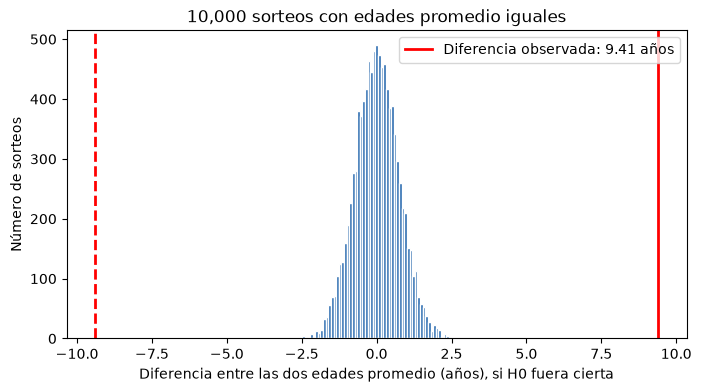

Diferencia más grande que produjo el azar: 2.75 años
Veces que salió una diferencia de 9.41 años o más (en cualquier dirección): 0


In [11]:
generador_h0 = np.random.default_rng(42)
edades_grupo_1 = generador_h0.normal(40, s_abandona, size=(10000, n_1))
edades_grupo_2 = generador_h0.normal(40, s_se_queda, size=(10000, n_2))
diferencias_bajo_h0 = edades_grupo_1.mean(axis=1) - edades_grupo_2.mean(axis=1)
veces_9_41_o_mas = (np.abs(diferencias_bajo_h0) >= diferencia_observada).sum()
figura, eje = plt.subplots(figsize=(8, 4))
eje.hist(diferencias_bajo_h0, bins=60, color="#2b6cb0", edgecolor="white")
eje.axvline(diferencia_observada, color="red", linewidth=2, label="Diferencia observada: 9.41 años")
eje.axvline(-diferencia_observada, color="red", linewidth=2, linestyle="--")
eje.set_xlabel("Diferencia entre las dos edades promedio (años), si H0 fuera cierta")
eje.set_ylabel("Número de sorteos")
eje.set_title("10,000 sorteos con edades promedio iguales")
eje.legend()
plt.show()
print("Diferencia más grande que produjo el azar:", round(np.abs(diferencias_bajo_h0).max(), 2), "años")
print("Veces que salió una diferencia de 9.41 años o más (en cualquier dirección):", veces_9_41_o_mas)

**Lectura:** si las edades promedio fueran iguales, el azar produce diferencias de, como mucho, unos 3 años. **Ninguno** de los 10,000 sorteos llegó a 9.41 años. La diferencia observada está lejísimos de lo que produce el azar.

### El rango explicable por azar
Analíticamente, el azar explica diferencias dentro de $0 \pm t \cdot EE$:

In [12]:
grados_libertad_dos_grupos = n_1 + n_2 - 2
t_critico_dos_grupos = stats.t.ppf(0.975, grados_libertad_dos_grupos)
rango_azar = t_critico_dos_grupos * error_estandar_diferencia
print("Grados de libertad (n1 + n2 - 2):", grados_libertad_dos_grupos)
print("Valor t crítico:", round(t_critico_dos_grupos, 4))
print("Rango explicable por azar: de", round(-rango_azar, 2), "a", round(rango_azar, 2), "años")

Grados de libertad (n1 + n2 - 2): 998
Valor t crítico: 1.9623
Rango explicable por azar: de -1.44 a 1.44 años


**De dónde sale:** 1.9623 × 0.7339 = ±1.44 años. La diferencia observada (9.41 años) está **fuera** de ese rango.

**Nota:** aquí se usan $gl = n_1 + n_2 - 2$ = 998, la versión de la guía. El proyecto usa los grados de libertad de Welch (338.6). Con estos tamaños, el valor t es casi el mismo: 1.962 contra 1.967.

### 🔗 Enlace con el documento · Apartados 5.4 y 6.1 (P4)

**Qué cubre esta lección del documento:** el documento pide **intervalos de confianza**, no pruebas de hipótesis. La prueba de esta lección es otra forma de leer el mismo resultado de P4:

| Lo que pide el documento (intervalo) | Lo que hace esta lección (prueba) | Relación |
|---|---|---|
| IC 95 % de la diferencia de edades: (8.0, 10.8) años | H0: diferencia = 0; se rechaza con p < 0.001 | El intervalo **no contiene el 0** ⇔ se rechaza H0 con α = 0.05 |

En la presentación se reporta el **intervalo** (es lo que pide el documento) y se puede añadir que la prueba lleva a la misma conclusión.

**Supuestos revisados:** grupos independientes (cada cliente está en un solo grupo), muestras grandes (206 y 794) y desviaciones estándar distintas (9.24 y 9.94). Por eso el proyecto usa el método de Welch, que no supone varianzas iguales.

### 📝 Mis notas

*Escribe aquí con tus palabras (doble clic para editar):*

1. Escribe H0 y H1 de P4 con palabras del problema (sin decir 'diferencia' sin decir de qué).
2. ¿Qué representa el histograma de la simulación?
3. ¿Por qué la diferencia de 9.41 años no se puede explicar por el azar?

- 
- 
- 

---
# Lección 7 · Una cola o dos colas

Depende de **cómo se redacta la pregunta**:

| Pregunta | Tipo | H1 | Qué cuenta como "extremo" |
|---|---|---|---|
| "¿La edad promedio de quienes abandonan es **distinta** a la de quienes se quedan?" | **Dos colas** | $\mu_{\text{abandona}} \neq \mu_{\text{se queda}}$ | Diferencias de 9.41 años o más **en cualquier dirección** (los que abandonan más viejos o más jóvenes) |
| "¿Los clientes que abandonan son **mayores** que los que se quedan?" | **Una cola** | $\mu_{\text{abandona}} > \mu_{\text{se queda}}$ | Sólo diferencias de +9.41 años o más |

```
Dos colas:   ███▁▁▁▂▅██████▅▂▁▁▁███      zona roja en las dos orillas (2.5 % en cada una)
Una cola:    ▁▁▁▁▂▅██████▅▂▁▁▁█████      zona roja sólo en la orilla derecha (5 %)
```

En la simulación de la Lección 6, las dos líneas rojas (+9.41 y −9.41) marcan las dos zonas de una prueba de dos colas.

**El proyecto usa dos colas**, porque la pregunta P4 es si las edades promedio son distintas, sin decir de antemano cuál grupo es mayor.

### 🔗 Enlace con el documento · Apartado 5

**Qué cubre esta lección del documento:** un intervalo de confianza al 95 % siempre corresponde a una prueba **de dos colas** con α = 0.05, porque deja 2.5 % fuera en cada orilla. Por eso P4 se plantea con dos colas: es la versión que coincide con el intervalo que pide el documento.

### 📝 Mis notas

*Escribe aquí con tus palabras (doble clic para editar):*

1. ¿Cuándo se usa una prueba de una cola y cuándo de dos colas?
2. ¿P4 es de una o de dos colas? ¿Por qué?

- 
- 
- 

---
# Lección 8 · El valor p

### La frase completa
> El valor p es: **suponiendo que en la población la edad promedio de quienes abandonan es igual a la de quienes se quedan**, la proporción de sorteos en que **la diferencia entre las dos edades promedio** saldría de **9.41 años o más** (en cualquier dirección).

Es exactamente el contador de la simulación: 0 de 10,000 veces.

### El estadístico t
Mide a cuántos errores estándar está la diferencia observada del 0 (el valor que dice H0):

$$t = \frac{\text{diferencia observada} - 0}{EE_{\text{diferencia}}}$$

In [13]:
estadistico_t = diferencia_observada / error_estandar_diferencia
p_valor = 2 * stats.t.sf(abs(estadistico_t), grados_libertad_dos_grupos)
print("Estadístico t:", round(estadistico_t, 2))
print("p-valor (dos colas):", p_valor)

Estadístico t: 12.82
p-valor (dos colas): 6.317635368146237e-35


**De dónde sale:** t = 9.41 / 0.7339 = **12.82**. La diferencia está a casi 13 errores estándar del 0. En la tabla, la última columna para muchos grados de libertad es 3.29 (para 0.001 de dos colas); como 12.82 es mucho mayor, se escribe **p < 0.001**.

**En Excel:** `=T.DIST.2T(12.82, 998)` da un número del orden de 10⁻³⁵ (0.00000…, con 34 ceros después del punto).

### La decisión: tres formas que siempre coinciden
| Criterio | Cálculo | Resultado |
|---|---|---|
| Rango explicable por azar | ¿9.41 está fuera de (−1.44, 1.44)? | Sí → rechazar H0 |
| Valor t contra t crítico | ¿12.82 > 1.962? | Sí → rechazar H0 |
| Valor p contra α | ¿p < 0.05? | Sí (p < 0.001) → rechazar H0 |

**Conclusión:** Se rechaza H0 (p < 0.001 < 0.05): en la población, la edad promedio de los clientes que abandonan es distinta (mayor) que la de los que se quedan.

### 🔗 Enlace con el documento · Apartados 6.1 y 6.4

**Significancia estadística contra importancia práctica.** El p-valor dice que la diferencia no se explica por azar. **No** dice si la diferencia es grande. Para eso se usa el tamaño del efecto:
- **d de Cohen = 0.96** (cuaderno 03). Se considera grande a partir de 0.8.
- En palabras del problema: 9.4 años es casi una desviación estándar de edad.

**Frase para la presentación:**
> Se rechaza H0 (p < 0.001 < 0.05): la edad promedio de los clientes que abandonan es mayor que la de los que se quedan. La diferencia es grande en la práctica (d = 0.96): con 95 % de confianza, quienes abandonan son entre 8.0 y 10.8 años mayores.

**Lo que hay que decir de la comprobación (apartado 6.4):** la diferencia real en los 10,000 clientes es **7.4 años**, que queda **fuera** del intervalo (8.0, 10.8). Es el único de los 4 intervalos que falló. Un 95 % de confianza admite que falle cerca de 1 de cada 20 intervalos. La conclusión de fondo se mantiene: quienes abandonan son mayores.

### 📝 Mis notas

*Escribe aquí con tus palabras (doble clic para editar):*

1. Escribe la frase completa del valor p de P4 sin usar 'eso' ni 'la diferencia' sin decir de qué.
2. ¿Qué mide el estadístico t = 12.82?
3. ¿Cuáles son los tres criterios de decisión y por qué siempre coinciden?

- 
- 
- 

---
# Lección 9 · Área bajo la curva = probabilidad

La curva t es el histograma de la simulación con infinitas repeticiones. En esa curva:
- **El área total es 1** (el 100 % de los sorteos posibles).
- **El área central** entre −1.962 y +1.962 es **0.95**: el nivel de confianza.
- **Las dos colas** fuera de ese rango suman **0.05**: es α.
- **El área más allá del t observado** (12.82 y −12.82) es el **valor p**.

In [14]:
area_central = stats.t.cdf(t_critico_dos_grupos, grados_libertad_dos_grupos) - stats.t.cdf(-t_critico_dos_grupos, grados_libertad_dos_grupos)
area_colas = 1 - area_central
area_mas_alla_del_t_observado = 2 * stats.t.sf(estadistico_t, grados_libertad_dos_grupos)
print("Área central (nivel de confianza):", round(area_central, 4))
print("Área de las dos colas (alfa):", round(area_colas, 4))
print("Área más allá de t = 12.82 en las dos colas (valor p):", area_mas_alla_del_t_observado)

Área central (nivel de confianza): 0.95
Área de las dos colas (alfa): 0.05
Área más allá de t = 12.82 en las dos colas (valor p): 6.317635368146237e-35


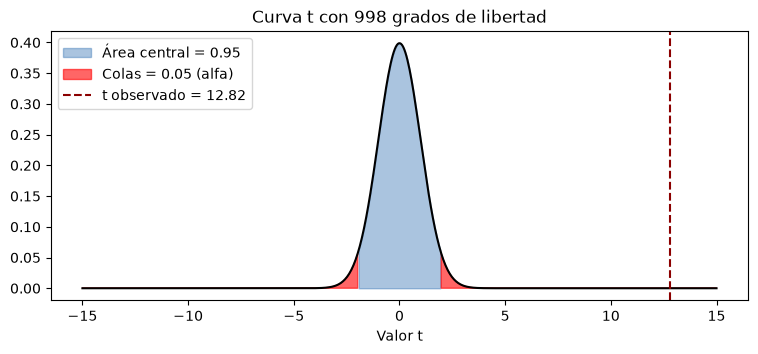

In [15]:
eje_x = np.linspace(-15, 15, 600)
curva = stats.t.pdf(eje_x, grados_libertad_dos_grupos)
figura, eje = plt.subplots(figsize=(9, 3.5))
eje.plot(eje_x, curva, color="black")
eje.fill_between(eje_x, curva, where=np.abs(eje_x) <= t_critico_dos_grupos, color="#2b6cb0", alpha=0.4, label="Área central = 0.95")
eje.fill_between(eje_x, curva, where=np.abs(eje_x) > t_critico_dos_grupos, color="red", alpha=0.6, label="Colas = 0.05 (alfa)")
eje.axvline(estadistico_t, color="darkred", linestyle="--", label="t observado = 12.82")
eje.set_xlabel("Valor t")
eje.set_title("Curva t con 998 grados de libertad")
eje.legend()
plt.show()

**Lectura:** el t observado (12.82) está tan lejos que el área a su derecha es prácticamente 0. Sumar el área de una zona de la curva es lo mismo que sumar las barras del histograma de la simulación en esa zona.

### 🔗 Enlace con el documento · Apartado 6.2

**Qué cubre esta lección del documento:** el área central de la curva es el **nivel de confianza** (0.95) y las colas son **α** (0.05). Cambiar el nivel de confianza (apartado 6.2) es mover las líneas que separan el centro de las colas:
- 90 % → valor crítico 1.645 → intervalo más estrecho, menos seguro.
- 95 % → valor crítico 1.96 → el que usa el proyecto.
- 99 % → valor crítico 2.576 → intervalo más ancho, más seguro.

### 📝 Mis notas

*Escribe aquí con tus palabras (doble clic para editar):*

1. ¿Qué representa el área central de la curva?
2. ¿Qué representan las colas?
3. ¿Dónde está el valor p en la curva?

- 
- 
- 

---
# Tabla resumen

| Concepto | Qué es | Valor en el proyecto |
|---|---|---|
| Población | Todo el grupo de interés | 10,000 clientes (2,037 abandonaron) |
| Muestra | La parte que se analiza | 1,000 clientes (206 abandonaron) |
| Parámetro μ | Valor de la población, desconocido | Saldo promedio real de quien abandona: 91,109 € |
| Estadístico x̄ | Valor de la muestra | 91,562 € |
| Desviación estándar s | Cuánto varían los clientes | 60,593 € (saldo); 9.24 y 9.94 años (edad) |
| Error estándar | Cuánto varía el promedio de una muestra a otra | 4,222 € (P2); 0.734 años (diferencia en P4) |
| Grados de libertad | Qué fila de la tabla leer | 205 (P2); 998 (P4) |
| Valor t crítico | Cuántos errores estándar cubren el 95 % | 1.9716 (P2); 1.962 (P4) |
| FCPF | Corrección cuando n es más del 5 % de N | 0.9487 |
| Intervalo de confianza | Estimación ± t × error estándar | P2: (83,665 €; 99,458 €) |
| H0 / H1 | Iguales / distintas | Edades promedio iguales / distintas |
| Estadístico t | Distancia de lo observado a H0, en errores estándar | 12.82 |
| Valor p | Probabilidad de ver algo así o más extremo si H0 fuera cierta | p < 0.001 |

# Receta de 6 pasos
1. **Escribe qué se midió**, a quién y qué salió, con números.
2. **Calcula el error estándar** (de un promedio, de una proporción o de una diferencia).
3. **Busca el valor crítico** (t o z) para tu nivel de confianza y tus grados de libertad.
4. **Calcula el margen**: valor crítico × error estándar (× FCPF si n/N > 5 %).
5. **Construye el intervalo** o **calcula el estadístico t y el valor p**.
6. **Escribe la conclusión** en una frase con las palabras del problema.

---
# Soluciones listas para entregar

## Solución P1 · Intervalo para una proporción
**Datos:** n = 1,000; clientes que abandonaron = 206; N = 10,000; confianza 95 %.
1. $\hat p$ = 206 / 1,000 = 0.206
2. $EE = \sqrt{0.206 \times 0.794 / 1000}$ = 0.0128
3. Valor crítico: $z$ = 1.96 (`=NORM.S.INV(0.975)`)
4. n/N = 10 % > 5 % → FCPF = 0.9487; EE corregido = 0.0121
5. Margen: $E$ = 1.96 × 0.0121 = 0.0238
6. Intervalo: 0.206 ± 0.0238 = **(0.182, 0.230)**

**Interpretación:** con 95 % de confianza, entre 18.2 % y 23.0 % de los clientes del banco abandonan.

## Solución P2 · Intervalo para una media
**Datos:** n = 206; $\bar x$ = 91,561.53 €; $s$ = 60,592.91 €; N = 10,000 (n/N de la muestra completa = 10 %).
1. $EE = 60{,}592.91 / \sqrt{206}$ = 4,221.71 €
2. Valor crítico: gl = 205; columna 0.05 dos colas; $t$ = 1.9716 (`=T.INV.2T(0.05, 205)`; con tabla, fila 120: 1.980)
3. FCPF = 0.9487; EE corregido = 4,005.26 €
4. Margen: $E$ = 1.9716 × 4,005.26 = 7,896.79 €
5. Intervalo: 91,561.53 ± 7,896.79 = **(83,664.74 €; 99,458.33 €)**

**Interpretación:** con 95 % de confianza, el saldo promedio de los clientes del banco que abandonan está entre 83,665 € y 99,458 €.

## Solución P4 · Prueba de hipótesis para dos medias
**Pregunta:** ¿la edad promedio de los clientes que abandonan es distinta a la de los que se quedan?

| | Abandonaron | Se quedaron |
|---|---|---|
| n | 206 | 794 |
| Edad promedio | 46.50 | 37.10 |
| s | 9.24 | 9.94 |

**Supuestos:** α = 0.05, dos colas, grupos independientes, muestras grandes.

1. **Hipótesis.** H0: $\mu_{\text{abandona}} = \mu_{\text{se queda}}$ (en la población, las dos edades promedio son iguales). H1: $\mu_{\text{abandona}} \neq \mu_{\text{se queda}}$ (son distintas).
2. **Error estándar:** $\sqrt{9.24^2/206 + 9.94^2/794}$ = 0.734 años.
3. **Valor crítico:** gl = 206 + 794 − 2 = 998; columna 0.05 dos colas; $t$ = 1.962 (fila ∞ de la tabla: 1.960).
4. **Rango explicable por azar:** 0 ± 1.962 × 0.734 = (−1.44, 1.44) años.
5. **Estadístico:** $t$ = (9.41 − 0) / 0.734 = 12.82.
6. **Valor p:** p < 0.001 (`=T.DIST.2T(12.82, 998)`).
7. **Decisión:** 9.41 está fuera del rango; 12.82 > 1.962; p < 0.05. Los tres criterios indican **rechazar H0**.
8. **Conclusión:** Se rechaza H0 (p < 0.001 < 0.05). La edad promedio de los clientes que abandonan es mayor que la de los que se quedan. Con 95 % de confianza, la diferencia está entre 8.0 y 10.8 años (intervalo del proyecto, con FCPF y grados de libertad de Welch).

## Nota sobre P3 (diferencia de proporciones)
Tiene la misma estructura que P4, cambiando el error estándar por el de proporciones:
$EE = \sqrt{\hat p_1(1-\hat p_1)/n_1 + \hat p_2(1-\hat p_2)/n_2}$ = $\sqrt{0.266 \times 0.734/463 + 0.155 \times 0.845/537}$ y usando $z$ en lugar de $t$. El resultado del proyecto es el intervalo **(0.063, 0.159)**: los inactivos abandonan entre 6.3 y 15.9 puntos porcentuales más que los activos.

---
# Del cuaderno a la presentación · Las conclusiones que hay que dar

Esta sección junta lo aprendido en las lecciones con los apartados 6, 7, 8 y Conclusiones del documento. Los números son los del reporte y los cuadernos 02 y 03.

## Paso 1 · Resultado de cada pregunta (apartados 5 y 6)

| Pregunta | Estimación puntual | IC 95 % | Valor real (comprobación) | ¿Acertó? |
|---|---|---|---|---|
| P1 · proporción que abandona | 0.206 | (0.182, 0.230) | 0.204 | Sí |
| P2 · saldo promedio de quien abandona | 91,562 € | (83,665 €; 99,458 €) | 91,109 € | Sí |
| P3 · inactivos − activos | 0.111 | (0.063, 0.159) | 0.126 | Sí |
| P4 · edad abandona − edad se queda | 9.4 años | (8.0, 10.8) | 7.4 años | No |

## Paso 2 · Conclusión literal de cada pregunta

**P1.** Con 95 % de confianza, entre el 18.2 % y el 23.0 % de los 10,000 clientes abandona el banco: entre unos 1,820 y 2,300 clientes. Es cerca de 1 de cada 5.

**P2.** Con 95 % de confianza, el saldo promedio de los clientes que abandonan está entre 83,665 € y 99,458 €.

**P3.** Con 95 % de confianza, la proporción de abandono de los clientes inactivos es entre 6.3 y 15.9 puntos porcentuales mayor que la de los activos. El intervalo no contiene el 0. Importancia práctica: el riesgo relativo es 1.72 (los inactivos abandonan 1.72 veces más). **Es una asociación, no una causa:** un cliente puede dejar de usar su cuenta porque ya planea irse.

**P4.** Con 95 % de confianza, quienes abandonan son entre 8.0 y 10.8 años mayores en promedio que quienes se quedan. El intervalo no contiene el 0 y el efecto es grande (d = 0.96). La diferencia real (7.4 años) quedó fuera del intervalo: es el fallo ocasional que admite el 95 %.

## Paso 3 · Comprobación con la población (apartado 6.4)

- **3 de 4** intervalos contienen el valor real.
- En la simulación del cuaderno 03, de 1,000 intervalos para P1, **946 (94.6 %)** contienen la proporción real. Es lo que promete un 95 % de confianza.
- Lo que hay que decir: el método acierta cerca de 95 de cada 100 veces, no siempre. El fallo de P4 muestra por qué se habla de **confianza** y no de **certeza**.

**Comprobación:** los 4 intervalos de la tabla del Paso 1 coinciden con la Tabla 9 del reporte.

## Paso 4 · De los intervalos a la decisión (apartado 7)

El documento pide que la decisión considere cinco cosas. Así aparece cada una:

| Lo que pide el documento | Cómo lo cumple el proyecto |
|---|---|
| La diferencia observada | Inactivos 26.6 % contra activos 15.5 % de abandono (P3) |
| El intervalo de confianza | Inactivos (0.227, 0.304); activos (0.126, 0.184) |
| La incertidumbre | Cada opción se evalúa en tres escenarios: límite inferior, estimación puntual y límite superior del intervalo |
| El costo | Contactar a un cliente cuesta 25 € (supuesto) |
| Las consecuencias de equivocarse | Lanzar sin que convenga cuesta como máximo unos 116 mil €. No lanzar cuando sí convenía deja ir clientes que se llevan entre 152 y 229 millones de € en depósitos |

**La regla de decisión.** Con costo $c$ = 25 €, efectividad $e$ = 25 % y valor del cliente $V$ = 500 € (los tres son supuestos), la campaña gana dinero si la tasa de abandono del grupo supera:

$$p^* = \frac{c}{e \cdot V} = \frac{25}{0.25 \times 500} = 0.20$$

| Grupo | IC 95 % de su tasa de abandono | Comparación con 0.20 | Decisión |
|---|---|---|---|
| Inactivos | (0.227, 0.304) | Todo el intervalo está por encima | La campaña conviene |
| Activos | (0.126, 0.184) | Todo el intervalo está por debajo | La campaña no conviene |

**Resultado:** la opción A2 (campaña sólo a inactivos) gana en los tres criterios: valor esperado (38,000 €), mejor peor caso (15,910 € contra 0 € de A1 y −34,061 € de A3) y mínimo arrepentimiento (0 €).

**Sensibilidad:** la decisión depende de la efectividad. A2 gana dinero en todo el intervalo sólo si la efectividad es de al menos **22 %**. El supuesto es 25 %: está por encima, pero cerca. Por eso se recomienda un piloto.

**Recomendación para la presentación:**
1. Lanzar la campaña de retención **sólo a clientes inactivos**.
2. No gastar presupuesto en los clientes activos.
3. Empezar con un **piloto con grupo de control** (por ejemplo, 500 inactivos con campaña y 500 sin ella, sorteados) para medir la efectividad real con su propio intervalo de confianza.
4. Investigar el mayor abandono en Alemania (cerca de 28 % contra 18 % en Francia y España).

## Paso 5 · Decisiones metodológicas (las 8 preguntas del documento)

El documento pide responderlas **con palabras propias**. Abajo está la idea clave de cada una y la lección del cuaderno que la explica. Reescríbelas con tu estilo.

| # | Pregunta del documento | Idea clave | Lección |
|---|---|---|---|
| 1 | ¿Por qué esa población? | La campaña aplica a toda la cartera: los 10,000 clientes de Francia, Alemania y España | 1 |
| 2 | ¿Por qué ese tamaño de muestra? | La fórmula con 95 %, ±3 puntos y p = 0.5 pide unos 965 clientes; se tomaron 1,000 | 2 |
| 3 | ¿Cómo se seleccionó a los participantes? | Muestreo aleatorio simple sin reemplazo, semilla 2026; la prueba χ² no encontró diferencias con la población (todos los p-valores > 0.05) | 1 |
| 4 | ¿Por qué esas técnicas? | Cada técnica corresponde al tipo de variable: proporción (sí/no), media con t (saldo), diferencia de proporciones (dos grupos), diferencia de medias de Welch (edades con varianzas distintas) | 3, 6 |
| 5 | ¿Por qué 95 % de confianza? | Equilibra precisión y seguridad; los errores de esta decisión son económicos y corregibles | 5, 9 |
| 6 | ¿Qué supuestos se consideraron? | Muestra aleatoria e independiente, muestras grandes (Teorema del Límite Central), registros correctos y costo, efectividad y valor supuestos | 3, 6 |
| 7 | ¿Qué limitaciones tiene el estudio? | Banco no identificado y sin fechas; estudio observacional (no prueba causas); el intervalo no cubre errores de registro; la confianza de que los 4 intervalos acierten a la vez es menor al 95 %; la efectividad de la campaña no se midió | 5, 8 |
| 8 | ¿Qué decisión puede tomar la organización? | Campaña de retención sólo a inactivos, empezando con un piloto controlado | Paso 4 |

## Paso 6 · Conclusión general (para cerrar la presentación)

> Con una muestra aleatoria de 1,000 clientes, el 10 % de la cartera, se estimaron cuatro valores de la población con su margen de error. Cerca de 1 de cada 5 clientes abandona el banco (entre 18.2 % y 23.0 %), y cada uno se lleva en promedio entre 83,665 € y 99,458 €. El abandono es mayor entre los clientes inactivos (entre 6.3 y 15.9 puntos más) y entre los de mayor edad (entre 8.0 y 10.8 años más). Al comparar con los 10,000 clientes, 3 de los 4 intervalos acertaron, como se espera de un 95 % de confianza. Con estos intervalos y los costos supuestos, la decisión es lanzar una campaña de retención sólo para clientes inactivos, empezando con un piloto que mida su efectividad real.

## Paso 7 · Guion corto de la exposición

| Orden | Qué decir | Número clave |
|---|---|---|
| 1 | El problema y por qué importa | Clientes que se van con su dinero |
| 2 | Población y muestra | N = 10,000; n = 1,000; semilla 2026 |
| 3 | Estimaciones puntuales | 0.206; 91,562 €; 0.111; 9.4 años |
| 4 | Intervalos de confianza | Tabla del Paso 1 |
| 5 | Qué significa el 95 % y la comprobación | 3 de 4 aciertan; 94.6 % en la simulación |
| 6 | La decisión | Umbral 0.20; A2; efectividad mínima 22 % |
| 7 | Limitaciones y recomendación | Asociación no es causa; piloto con grupo de control |

### 📝 Mis notas

*Escribe aquí con tus palabras (doble clic para editar):*

1. Escribe la receta de 6 pasos aplicada a P3.
2. ¿Por qué la campaña conviene en los inactivos y no en los activos? Usa los dos intervalos y el umbral 0.20.
3. ¿Qué dirías si el profesor pregunta por qué falló el intervalo de P4?
4. Escribe con tus palabras la respuesta a la pregunta 7 de decisiones metodológicas (limitaciones).

-
-
-
- 